# 04 · Resultados y evaluación

Fase CRISP-DM: **Evaluación**.

Compara todos los modelos con las mismas fotos. Primero se genera la evaluación:
```
python -m src.main evaluar          # val: se puede repetir
```
Y solo al final, una vez:
```
python -m src.main congelar
python -m src.main evaluar --test --confirmo
```

**Cómo leer las métricas**
- **F1 macro**: promedio del F1 de good, regular y bad. Así la clase con menos fotos (regular) pesa lo mismo que las demás.
- **Malas como buenas**: frutas malas que el modelo dejaría pasar como buenas. Es el error más caro para el negocio.
- **IC 95 %**: rango probable del F1 si se repitiera con otras fotos. Se calcula remuestreando **grupos** completos, porque las fotos de un grupo se parecen entre sí.

In [9]:
from pathlib import Path
import json
import sys

root = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "src" / "config.py").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import matplotlib.pyplot as plt
import pandas as pd

from src import config

def read(name):
    """Lee un resultado de results/; si no existe, explica qué comando lo genera."""
    path = config.RESULTS / name
    if not path.is_file():
        raise FileNotFoundError(f"Falta {path}. Corre primero los pasos del README.")
    return json.loads(path.read_text(encoding="utf-8"))

config.FIGURES.mkdir(parents=True, exist_ok=True)

In [10]:
partition = "test" if (config.RESULTS / "evaluacion_test.json").is_file() else "val"
report = read(f"evaluacion_{partition}.json")
print(f"Partición: {partition} · {report['n']} recortes en {report['n_groups']} grupos")
pd.DataFrame([{"modelo": name, "F1 macro": round(m["f1_macro"], 3),
               "F1 Kaggle (2 clases)": round(m.get("f1_kaggle", float("nan")), 3),
               "F1 AgriFreshNET (3 clases)": round(m.get("f1_agrifreshnet", float("nan")), 3),
               "F1 AFruitDB (3 clases)": round(m.get("f1_afruitdb", float("nan")), 3),
               "recall bad": round(m["recall_bad"], 3), "malas como buenas": m["bad_to_good"]}
              for name, m in report["models"].items()])

Partición: test · 4169 recortes en 184 grupos


,modelo,F1 macro,F1 Kaggle (2 clases),F1 AgriFreshNET (3 clases),F1 AFruitDB (3 clases),recall bad,malas como buenas
0,logistic_regression,0.560,0.865,0.433,0.373,0.782,86
1,svm_linear,0.566,0.880,0.460,0.348,0.815,80
2,random_forest,0.596,0.932,0.431,0.613,0.871,40
3,cnn,0.603,0.903,0.499,0.472,0.771,190
4,ensemble,0.621,0.929,0.513,0.539,0.832,101


In [11]:
final = report.get("final_model", "random_forest")
lo, hi = report["models"][final]["f1_macro_ci95"]
print(f"Modelo final ({final}): F1 {report['models'][final]['f1_macro']:.3f}, IC 95 % [{lo:.3f}; {hi:.3f}]")
print(f"Fruta: accuracy {report['fruit']['accuracy']:.3f}, F1 macro {report['fruit']['f1_macro']:.3f}")

Modelo final (random_forest): F1 0.596, IC 95 % [0.522; 0.677]
Fruta: accuracy 0.795, F1 macro 0.755


## ¿El modelo aprendió `regular` o el estilo de una fuente?

Casi todos los `regular` vienen de AgriFreshNET. Si el modelo acierta `regular` en AgriFreshNET pero no en AFruitDB (otra fuente, con fotos de celular), aprendió el estilo de AgriFreshNET y no el estado de la fruta. Cada celda es el porcentaje de frutas `regular` reales que el modelo llamó `regular`.

In [12]:
pd.DataFrame({name: m.get("recall_regular_by_source", {}) for name, m in report["models"].items()}).T.mul(100).round(1)

,afruitdb,agrifreshnet
logistic_regression,51.4,26.0
svm_linear,24.3,21.1
random_forest,94.6,22.6
cnn,45.9,19.8
ensemble,54.1,21.1


## Por fruta: dónde acierta y dónde falla

Para cada fruta: cuántas fotos hay, qué tanto acierta la fruta, qué tanto acierta el estado el modelo final y qué parte de las `regular` reales llama `bad`.

In [13]:
pred = pd.read_csv(config.RESULTS / f"predicciones_{partition}.csv")
col = f"{final}_prediction"
rows = []
for product, g in pred.groupby("product"):
    regular = g[g["quality"] == "regular"]
    rows.append({"fruta": product, "fotos": len(g),
                 "acierta fruta %": round(100 * (g["fruit_prediction"] == product).mean(), 1),
                 "acierta estado %": round(100 * (g[col] == g["quality"]).mean(), 1),
                 "regular reales": len(regular),
                 "regular → bad %": round(100 * (regular[col] == "bad").mean(), 1) if len(regular) else None})
pd.DataFrame(rows).sort_values("acierta estado %")

,fruta,fotos,acierta fruta %,acierta estado %,regular reales,regular → bad %
4,eggplant,23,91.3,0.0,17,88.2
9,papaya,255,77.3,31.8,36,2.8
10,pineapple,347,89.9,32.6,220,93.2
2,bitter_melon,443,98.4,37.7,119,6.7
3,cucumber,506,24.9,38.9,207,87.0
7,mango,47,78.7,44.7,0,NaN
12,tomato,128,85.2,64.1,42,4.8
1,banana,640,99.1,72.5,181,88.4
0,apple,428,76.9,83.9,1,0.0
11,pomegranate,328,87.8,92.7,0,NaN


## Matrices de confusión

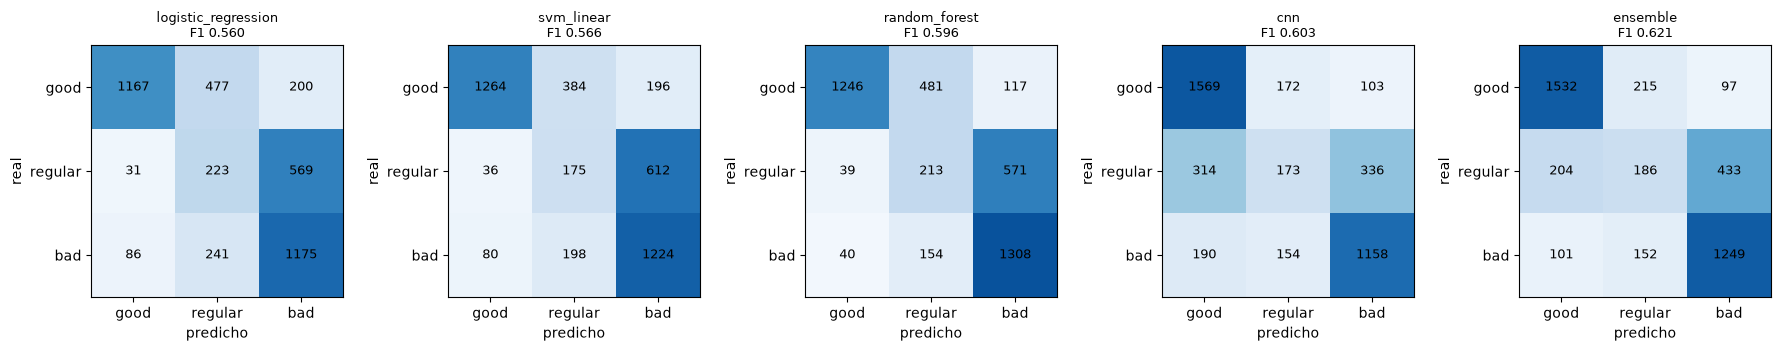

In [14]:
import numpy as np

names = list(report["models"])
fig, axes = plt.subplots(1, len(names), figsize=(3.6 * len(names), 3.4))
for ax, name in zip(axes, names):
    m = report["models"][name]
    matrix = np.asarray(m["confusion_matrix"])
    ax.imshow(matrix / matrix.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(3), m["labels"]); ax.set_yticks(range(3), m["labels"])
    for i in range(3):
        for j in range(3):
            ax.text(j, i, matrix[i, j], ha="center", va="center", fontsize=9)
    ax.set_title(f"{name}\nF1 {m['f1_macro']:.3f}", fontsize=9)
    ax.set_xlabel("predicho"); ax.set_ylabel("real")
fig.tight_layout()
fig.savefig(config.FIGURES / f"confusion_{partition}.png", dpi=150)

## Fruta: qué se confunde con qué

In [15]:
fruit = report["fruit"]
pd.DataFrame(fruit["confusion_matrix"], index=fruit["labels"], columns=fruit["labels"])

,apple,banana,bitter_melon,cucumber,eggplant,guava,lime,mango,orange,papaya,pineapple,pomegranate,tomato
apple,329,8,0,0,1,0,0,0,17,0,0,58,15
banana,1,634,2,0,0,0,1,0,1,0,1,0,0
bitter_melon,0,0,436,0,0,0,0,0,0,2,5,0,0
cucumber,1,1,9,126,10,0,0,0,135,200,23,0,1
eggplant,0,1,0,0,21,0,0,0,0,0,0,1,0
guava,9,30,8,0,11,142,29,0,3,2,1,1,0
lime,11,23,0,1,1,2,190,0,36,0,0,0,0
mango,0,0,0,0,2,0,0,37,0,8,0,0,0
orange,19,6,1,0,2,0,1,0,493,2,0,0,0
papaya,0,7,14,0,6,0,0,20,11,197,0,0,0


## Prueba de fuga (opcional): `python -m src.main fuga`

Misma validación cruzada, cambiando solo cómo se agrupan las fotos de AgriFreshNET. Si el F1 baja al agrupar más grueso, con grupos finos la nota estaba inflada. La última columna debe dar 0 en "week": ninguna foto de val comparte semana con train.

In [16]:
if (config.RESULTS / "prueba_fuga.json").is_file():
    leak = read("prueba_fuga.json")
    display(pd.DataFrame([{"agrupación": level, "grupos en train": item["train_groups"],
                           "F1 AgriFreshNET": round(item["cv"]["agrifreshnet_3cl"]["mean"], 3),
                           "F1 global": round(item["cv"]["overall"]["mean"], 3),
                           "val que comparte sesión con train":
                               item["crossing"]["val_agri_rows_sharing_session_with_train"]}
                          for level, item in leak["levels"].items()]))
else:
    print("Aún no se corrió la prueba de fuga.")

Aún no se corrió la prueba de fuga.


## Fotos de celular, mitad "prueba": `python -m src.main celular evaluar --confirmo`

La prueba más cercana al uso real: fotos tomadas por la clase con celulares, de sesiones que el modelo nunca vio (la otra mitad de las sesiones sí entrenó), con el estado etiquetado sin mirar la app.

In [17]:
if (config.RESULTS / "evaluacion_celular.json").is_file():
    phone = read("evaluacion_celular.json")
    print(f"{phone['n']} fotos de {phone['sessions']} sesiones · "
          f"fruta: accuracy {phone['fruit']['accuracy']:.3f} {phone['fruit']['accuracy_ci95']}")
    display(pd.DataFrame([{"modelo": n, "F1 macro": round(q["f1_macro"], 3),
                           "IC 95 %": [round(v, 3) for v in q["f1_macro_ci95"]],
                           "malas como buenas": q["bad_to_good"]}
                          for n, q in phone["quality"].items()]))
    display(pd.DataFrame([{"fruta": product, "fotos": item["n"],
                           "acierta fruta %": round(100 * item["fruit_accuracy"], 1),
                           "F1 estado (modelo final)": round(item["quality_f1_final"], 3),
                           "¿fotos de celular en train?": "sí" if item["phone_photos_in_training"] else "no"}
                          for product, item in phone["by_product"].items()]))
else:
    print("Aún no se evaluaron las fotos de celular.")

302 fotos de 6 sesiones · fruta: accuracy 0.318 [0.052770448548812667, 0.7644628099173554]


,modelo,F1 macro,IC 95 %,malas como buenas
0,random_forest,0.295,"[0.227, 0.334]",2
1,cnn,0.308,"[0.229, 0.37]",2
2,ensemble,0.310,"[0.245, 0.359]",2


,fruta,fotos,acierta fruta %,F1 estado (modelo final),¿fotos de celular en train?
0,apple,35,88.6,0.226,sí
1,banana,18,100.0,0.035,sí
2,guava,91,1.1,0.314,no
3,lime,70,0.0,0.333,no
4,mango,39,0.0,0.222,no
5,orange,49,93.9,0.287,no


## Lectura de los resultados finales (26-nov-2026)

**Test** (4.169 recortes, 184 grupos; abierto una sola vez):
- Random Forest, el modelo final elegido en val: F1 macro **0,596** [0,522 – 0,677], 40 frutas malas como buenas, fruta acertada en el 79,5 %. En val tenía 0,762.
- La caída viene de AgriFreshNET: en Kaggle el F1 sigue en 0,93. De los 786 `regular` de AgriFreshNET en test, RF llama `bad` a 570. Sobre todo en banano, pepino, piña y berenjena, con 87–93 % cada uno (la berenjena de val, de otro lote, no tenía ese problema).
- La razón es el tamaño real de la muestra. Casi todos los productos de AgriFreshNET tienen solo de 2 a 5 lotes (semanas) de `regular` (la berenjena, 21). A val le tocaron lotes de naranja, papaya, tomate y berenjena, que RF generaliza bien. A test le tocaron lotes de banano, pepino y piña, cuyo `regular` se parece más a `bad`. Con tan pocos lotes, val y test pueden diferir mucho por cuáles caen en cada lado. Por eso los intervalos son anchos y test es la cifra que se sustenta.
- RF sigue siendo el que menos malas deja pasar: 40, frente a 101 del ensamble y 190 de la CNN. En test el ensamble saca más F1 (0,621), pero la elección se hizo antes y no se cambia.

**Fotos de celular, mitad "prueba"** (302 fotos, 6 sesiones):
- Fruta: 31,8 % en total. Pero manzana (89 %) y banano (100 %), que tuvieron fotos de celular en train, se reconocen. Guayaba, limón y mango, que no, quedan cerca de 0 %: el modelo llama "naranja" a limones y guayabas amarillo-verdosos, y "papaya" al mango. Los recortes se revisaron a mano y son correctos: es cambio de dominio, no un error del código.
- Estado: F1 macro 0,295. Casi todas las buenas salen buenas, pero no detecta `regular`. Solo hay 4 malas, todas de mango, y ninguna se detectó: con 4 casos esa cifra no permite concluir nada.
- Conclusión: **las fotos de celular de una fruta en train son lo que más ayuda.** Con la mitad "entrenar" la manzana y el banano pasaron a reconocerse; las frutas que solo estaban en "prueba" no.